# 🏠 Intelligent Property Search & Decision Agent

A **stateful multi-agent system** built with **LangGraph** that helps a user find and select the
best rental property in Delhi based on natural-language requirements (budget, location, BHK,
furnishing, commute, risk tolerance, etc.).

**Architecture**

```
START -> Requirement Agent -> Planner Agent -> Property Search Agent
                                                        |
                     -----------------------------------------------------------------
                     |                |                    |                        |
           Location & Commute   Market Price          Neighborhood              Verification
                Agent               Agent                 Agent                    Agent
                     |                |                    |                        |
                     -----------------------------------------------------------------
                                                        |
                                                   Risk Agent  (fan-in)
                                                        |
                                                  Ranking Agent
                                                        |
                                                  Decision Agent
                                                        |
                                              Human Review (interrupt)
                                              /                       \
                                     approved -> END        rejected -> back to Requirement Agent
                                                              (dynamic replanning: only affected
                                                               agents re-run)
```

* `Property Search`, `Location & Commute`, `Market Price`, `Neighborhood`, `Verification` run in
  **parallel**, exactly like the *Parallel Workflow* pattern.
* `Risk Agent` is a **fan-in** node, like the *Combined/Final report* pattern.
* `Human Review` uses LangGraph's `interrupt()` / `Command(resume=...)`, like the *Interrupt*
  pattern.
* `Planner Agent` compares the new requirements against the previous ones and marks which
  specialist agents actually need to re-run → **dynamic replanning** without wasting LLM/API
  calls on agents whose inputs didn't change.
* In production, `Property Search`, `Location & Commute`, `Market Price`, `Neighborhood` would
  call real **MCP tools** (listing sites, Google Maps, review sites, pricing APIs). Here we use a
  local CSV as the listings source, a small landmark lookup + haversine formula as a maps
  stand-in, and **Tavily web search** for neighborhood/market intelligence — swap these for real
  MCP tool calls when you wire this up to actual services.
* Add **LangSmith** tracing by setting `LANGCHAIN_TRACING_V2=true` and `LANGCHAIN_API_KEY` in your
  `.env` — no code changes needed.


## 0. Setup

In [1]:
# Run once
# !pip install langgraph langchain-openai langchain-tavily langchain-core python-dotenv pandas

In [2]:
from langchain_openai import ChatOpenAI
from langchain_core.messages import HumanMessage, SystemMessage
from langchain_tavily import TavilySearch
from dotenv import load_dotenv
from langgraph.graph import StateGraph, START, END
from langgraph.types import interrupt, Command
from langgraph.checkpoint.memory import MemorySaver
from typing import TypedDict, List, Dict, Any, Optional

import os, re, json, math
import pandas as pd

In [3]:
load_dotenv()   # expects OPENAI_API_KEY and TAVILY_API_KEY in your .env

assert os.getenv("OPENAI_API_KEY"), "OPENAI_API_KEY not found — put it in your .env"
assert os.getenv("TAVILY_API_KEY"), "TAVILY_API_KEY not found — put it in your .env"
print("Keys loaded ✅")

Keys loaded ✅


## 1. Load & Prepare Property Data
This stands in for the **Property Search MCP tool** (a real listings API/MCP server).
We clean up the raw scraped columns (`house_type`, `house_size`, `SecurityDeposit`,
`verificationDate` ...) into usable numeric/categorical fields.

In [4]:
df_raw = pd.read_csv("Indian_housing_Delhi_data.csv")

def parse_bhk(house_type):
    if not isinstance(house_type, str):
        return None
    m = re.match(r"(\d+)\s*(BHK|RK)", house_type.strip(), re.IGNORECASE)
    return int(m.group(1)) if m else None

def parse_size(size_str):
    if not isinstance(size_str, str):
        return None
    try:
        return float(size_str.replace(",", "").lower().replace("sq ft", "").strip())
    except ValueError:
        return None

def parse_deposit(dep):
    if not isinstance(dep, str):
        return 0.0
    dep = dep.strip()
    if "no deposit" in dep.lower():
        return 0.0
    try:
        return float(dep.replace(",", "").strip())
    except ValueError:
        return None

def parse_days_ago(v):
    if not isinstance(v, str):
        return None
    m = re.search(r"(a|an|\d+)\s*(day|month|year)", v.lower())
    if not m:
        return None
    num = 1 if m.group(1) in ("a", "an") else int(m.group(1))
    mult = {"day": 1, "month": 30, "year": 365}[m.group(2)]
    return num * mult

df = df_raw.copy()
df["bhk"] = df["house_type"].apply(parse_bhk)
df["size_sqft"] = df["house_size"].apply(parse_size)
df["deposit_amt"] = df["SecurityDeposit"].apply(parse_deposit)
df["days_since_posted"] = df["verificationDate"].apply(parse_days_ago)
df["location_clean"] = df["location"].astype(str).str.strip()
df["price_per_sqft"] = df["price"] / df["size_sqft"]
df["is_negotiable"] = df["isNegotiable"].notna()
df = df.dropna(subset=["price_per_sqft", "bhk", "latitude", "longitude"])

# Locality-level average price/sqft, used later by the Market Price Agent
LOCALITY_AVG_PSF = df.groupby("location_clean")["price_per_sqft"].mean().to_dict()

print(f"{len(df)} usable listings after cleaning")
df[["house_type", "bhk", "location_clean", "price", "price_per_sqft", "Status"]].head()

5000 usable listings after cleaning


,house_type,bhk,location_clean,price,price_per_sqft,Status
0,1 RK Studio Apartment,1,Kalkaji,22000,55.000000,Furnished
1,1 RK Studio Apartment,1,Mansarover Garden,20000,50.000000,Furnished
2,2 BHK Independent Floor,2,Uttam Nagar,8500,17.000000,Semi-Furnished
3,3 BHK Independent House,3,Model Town,48000,47.058824,Furnished
4,2 BHK Apartment,2,Sector 13 Rohini,20000,24.691358,Unfurnished


## 2. Shared Tools (stand-ins for Maps / Web-search MCP servers)

* `find_landmark` + `haversine_km` → stand-in for a **Maps MCP tool** giving commute distance.
* `web_search` → wraps **Tavily** for the Neighborhood & Market agents' web research.

In [5]:
LANDMARKS = {
    "connaught place": (28.6315, 77.2167),
    "cyber city gurgaon": (28.4950, 77.0890),
    "cyber hub gurgaon": (28.4950, 77.0890),
    "gurgaon": (28.4595, 77.0266),
    "noida sector 62": (28.6272, 77.3716),
    "noida": (28.5355, 77.3910),
    "aiims": (28.5672, 77.2100),
    "delhi airport": (28.5562, 77.1000),
    "dwarka": (28.5921, 77.0460),
    "rohini": (28.7041, 77.1025),
    "gurugram": (28.4595, 77.0266),
}

def find_landmark(name: Optional[str]):
    if not name:
        return None
    name_l = name.lower().strip()
    for key, coord in LANDMARKS.items():
        if name_l in key or key in name_l:
            return coord
    return None

def haversine_km(lat1, lon1, lat2, lon2):
    R = 6371
    p1, p2 = math.radians(lat1), math.radians(lat2)
    dphi, dlmb = math.radians(lat2 - lat1), math.radians(lon2 - lon1)
    a = math.sin(dphi / 2) ** 2 + math.cos(p1) * math.cos(p2) * math.sin(dlmb / 2) ** 2
    return 2 * R * math.asin(math.sqrt(a))

tavily = TavilySearch(max_results=3)

def web_search(query: str) -> str:
    """Safe wrapper around Tavily — returns a short joined snippet, empty string on failure."""
    try:
        res = tavily.invoke({"query": query})
        results = res.get("results", []) if isinstance(res, dict) else res
        snippets = [r.get("content", "")[:300] for r in results[:2]]
        return " | ".join(s for s in snippets if s)
    except Exception as e:
        return f"(web search unavailable: {e})"

## 3. LLM

In [6]:
llm = ChatOpenAI(model="gpt-4o-mini", temperature=0)

## 4. Shared Agent State

Every node reads from and writes to this single `TypedDict`, exactly like the reference
workflows (`State`, `Emailstate`, ...).

In [7]:
class PropertyState(TypedDict):
    user_query: str                     # latest natural-language input from the user
    requirements: dict                  # structured constraints (this turn)
    previous_requirements: Optional[dict]  # structured constraints (last turn), for replanning
    changed_fields: List[str]
    agents_to_run: Dict[str, bool]      # planner's decision on which specialist agents to run
    candidates: List[dict]              # shortlisted properties from Property Search Agent
    location_report: Dict[str, Any]
    price_report: Dict[str, Any]
    neighborhood_report: Dict[str, Any]
    verification_report: Dict[str, Any]
    risk_report: Dict[str, Any]
    ranked: List[dict]
    decision: str
    human_feedback: str
    iteration: int

## 5. Requirement Agent
Turns free-text (`"2BHK in Rohini or Dwarka under 35k, low risk, close to Cyber City"`) into a
structured constraints dict. Keeps the previous requirements around so the Planner can diff them.

In [8]:
REQUIREMENT_SYSTEM_PROMPT = """You are a real-estate requirement extraction agent.
Read the user's message (which may add to or modify earlier requirements) and return ONLY a
JSON object (no markdown fences, no extra text) with these keys:
  budget_min (int or null), budget_max (int or null), bhk (int or null),
  locations (list of strings, empty list if unspecified),
  furnishing (one of "Furnished","Semi-Furnished","Unfurnished" or null),
  commute_landmark (string or null), max_commute_km (int or null),
  amenities (list of strings), risk_tolerance (one of "low","medium","high", default "medium")

If the user is only tweaking one thing (e.g. "increase budget to 40000"), carry over the rest of
the previous requirements unchanged."""

def requirement_agent(state: PropertyState):
    prev = state.get("requirements")
    # On a replan loop, the "new message" is the human's review feedback (e.g. "raise budget to
    # 45000"), not the original query. On the very first turn it's the original user_query.
    incoming_message = state.get("human_feedback") or state["user_query"]
    context = f"\nPrevious requirements: {json.dumps(prev)}" if prev else ""
    resp = llm.invoke([
        SystemMessage(content=REQUIREMENT_SYSTEM_PROMPT),
        HumanMessage(content=f"User message: {incoming_message}{context}")
    ])
    raw = resp.content.strip().strip("`").replace("json\n", "", 1)
    try:
        new_req = json.loads(raw)
    except json.JSONDecodeError:
        new_req = prev or {}
    return {
        "requirements": new_req,
        "previous_requirements": prev,
        "iteration": state.get("iteration", 0) + 1,
    }

## 6. Planner Agent — dynamic replanning
Diffs the new requirements against the previous ones and decides which specialist agents
actually need to (re)run. Location-sensitive agents only re-run if location/commute changed;
price-sensitive agents only re-run if the budget changed; Property Search & Verification always
run (cheap / safety-critical).

In [9]:
LOCATION_SENSITIVE = {"locations", "commute_landmark", "max_commute_km"}
PRICE_SENSITIVE = {"budget_min", "budget_max"}

def planner_agent(state: PropertyState):
    req, prev = state["requirements"], state.get("previous_requirements")
    if not prev:
        changed = list(req.keys())
    else:
        changed = [k for k in req if req.get(k) != prev.get(k)]

    plan = {
        "location_commute": (not prev) or bool(LOCATION_SENSITIVE & set(changed)),
        "market_price": (not prev) or bool(PRICE_SENSITIVE & set(changed)),
        "neighborhood": (not prev) or bool(LOCATION_SENSITIVE & set(changed)),
        "verification": True,   # always re-verify the (possibly new) shortlist
    }
    return {"changed_fields": changed, "agents_to_run": plan}

## 7. Property Search Agent
Filters the local listings dataset by the current requirements.

In [10]:
def property_search_agent(state: PropertyState):
    req = state["requirements"]
    sub = df.copy()
    if req.get("bhk"):
        sub = sub[sub["bhk"] == req["bhk"]]
    if req.get("budget_min"):
        sub = sub[sub["price"] >= req["budget_min"]]
    if req.get("budget_max"):
        sub = sub[sub["price"] <= req["budget_max"]]
    if req.get("locations"):
        pattern = "|".join(re.escape(l) for l in req["locations"])
        sub = sub[sub["location_clean"].str.contains(pattern, case=False, na=False)]
    if req.get("furnishing"):
        sub = sub[sub["Status"].str.lower() == req["furnishing"].lower()]

    sub = sub.sort_values("price").head(8).reset_index()
    candidates = [{"id": str(r["index"]), **r.to_dict()} for _, r in sub.iterrows()]
    return {"candidates": candidates}

## 8. Parallel Specialist Agents
`Location & Commute`, `Market Price`, `Neighborhood`, `Verification` all read the same
`candidates` list produced by Property Search and run **in parallel** (LangGraph fans them all
out from the same node, exactly like the *Parallel Workflow* example).

In [11]:
def location_commute_agent(state: PropertyState):
    if not state["agents_to_run"].get("location_commute", True):
        return {}   # skipped by planner — reuse whatever was already in state
    landmark = find_landmark(state["requirements"].get("commute_landmark"))
    max_km = state["requirements"].get("max_commute_km")
    report = {}
    for c in state["candidates"]:
        if landmark:
            d = round(haversine_km(c["latitude"], c["longitude"], *landmark), 1)
            report[c["id"]] = {"distance_km": d, "within_limit": d <= max_km if max_km else None}
        else:
            report[c["id"]] = {"distance_km": None, "within_limit": None}
    return {"location_report": report}

In [12]:
def market_price_agent(state: PropertyState):
    if not state["agents_to_run"].get("market_price", True):
        return {}
    report = {}
    for c in state["candidates"]:
        avg = LOCALITY_AVG_PSF.get(c["location_clean"])
        diff_pct = round((c["price_per_sqft"] - avg) / avg * 100, 1) if avg else None
        report[c["id"]] = {"locality_avg_psf": round(avg, 1) if avg else None, "diff_pct": diff_pct}
    return {"price_report": report}

In [13]:
def neighborhood_agent(state: PropertyState):
    if not state["agents_to_run"].get("neighborhood", True):
        return {}
    report, cache = {}, {}
    for c in state["candidates"]:
        loc = c["location_clean"]
        if loc not in cache:
            cache[loc] = web_search(f"{loc} Delhi neighborhood safety connectivity amenities review")
        report[c["id"]] = {"summary": cache[loc]}
    return {"neighborhood_report": report}

In [14]:
def verification_agent(state: PropertyState):
    """Rule-based cross-checks on the listing data (stand-in for a Verification MCP tool
    that would cross-check listing photos/registry/agent history etc.)."""
    report = {}
    for c in state["candidates"]:
        flags = []
        avg = LOCALITY_AVG_PSF.get(c["location_clean"])
        if avg and (c["price_per_sqft"] < avg * 0.5 or c["price_per_sqft"] > avg * 2):
            flags.append("price_outlier")
        if (c.get("days_since_posted") or 0) > 365:
            flags.append("stale_listing")
        if pd.isna(c.get("deposit_amt")):
            flags.append("missing_deposit_info")
        report[c["id"]] = {"flags": flags, "status": "Flagged" if flags else "OK"}
    return {"verification_report": report}

## 9. Risk Agent (fan-in)
Combines the four parallel reports into a single risk score per candidate, weighted by the user's risk tolerance.

In [15]:
RISK_WEIGHT = {"low": 1.5, "medium": 1.0, "high": 0.6}

def risk_agent(state: PropertyState):
    weight = RISK_WEIGHT.get(state["requirements"].get("risk_tolerance", "medium"), 1.0)
    report = {}
    for c in state["candidates"]:
        cid = c["id"]
        score = 0
        if state.get("verification_report", {}).get(cid, {}).get("status") == "Flagged":
            score += 30
        diff_pct = state.get("price_report", {}).get(cid, {}).get("diff_pct")
        if diff_pct is not None and abs(diff_pct) > 40:
            score += 20
        if state.get("location_report", {}).get(cid, {}).get("within_limit") is False:
            score += 15
        report[cid] = {"risk_score": round(score * weight, 1)}
    return {"risk_report": report}

## 10. Ranking Agent — multi-criteria scoring

In [16]:
def ranking_agent(state: PropertyState):
    ranked = []
    for c in state["candidates"]:
        cid = c["id"]
        risk = state.get("risk_report", {}).get(cid, {}).get("risk_score", 0)
        diff_pct = state.get("price_report", {}).get(cid, {}).get("diff_pct")
        within_limit = state.get("location_report", {}).get(cid, {}).get("within_limit")

        score = 100 - risk
        if diff_pct is not None:
            score += max(0, -diff_pct)   # reward being cheaper than the locality average
        if within_limit:
            score += 15

        ranked.append({**c, "final_score": round(score, 1)})

    ranked.sort(key=lambda x: x["final_score"], reverse=True)
    return {"ranked": ranked[:5]}

## 11. Decision Agent — LLM writes the final recommendation

In [17]:
def _summarize_for_llm(state: PropertyState) -> str:
    lines = []
    for c in state["ranked"][:5]:
        cid = c["id"]
        loc_r = state.get("location_report", {}).get(cid, {})
        price_r = state.get("price_report", {}).get(cid, {})
        risk_r = state.get("risk_report", {}).get(cid, {})
        verif = state.get("verification_report", {}).get(cid, {})
        lines.append(
            f"- [{cid}] {c['bhk']}BHK in {c['location_clean']}, Rs.{c['price']}/mo, "
            f"{c['size_sqft']}sqft, {c.get('Status')}, "
            f"commute={loc_r.get('distance_km')}km, "
            f"price_vs_locality={price_r.get('diff_pct')}%, "
            f"risk_score={risk_r.get('risk_score')}, "
            f"verification={verif.get('status')} {verif.get('flags')}"
        )
    return "\n".join(lines)

DECISION_SYSTEM_PROMPT = """You are the final decision agent of a property search assistant.
Given the user's requirements and a ranked shortlist with scores, write a short final
recommendation (max ~120 words): name the top pick, justify it in 2-3 bullet points using the
numbers given, then briefly mention 1-2 alternatives and their trade-offs."""

def decision_agent(state: PropertyState):
    resp = llm.invoke([
        SystemMessage(content=DECISION_SYSTEM_PROMPT),
        HumanMessage(content=(
            f"User requirements: {json.dumps(state['requirements'])}\n\n"
            f"Ranked shortlist:\n{_summarize_for_llm(state)}"
        )),
    ])
    return {"decision": resp.content}

## 12. Human-in-the-loop Review

Same `interrupt()` / `Command(resume=...)` pattern as the reference `email_agent`. The graph
pauses after the Decision Agent and waits for the user to approve or push back.

In [18]:
def human_review(state: PropertyState):
    feedback = interrupt({
        "question": "Approve this recommendation? Reply 'yes' to accept, or describe what to change.",
        "decision": state["decision"],
    })
    return {"human_feedback": feedback}

def route_after_review(state: PropertyState):
    fb = (state.get("human_feedback") or "").lower()
    if "yes" in fb or "approve" in fb:
        return "END"
    # anything else is treated as new/updated requirements -> loop back and replan
    return "requirement_agent"

## 13. Build & Compile the Graph

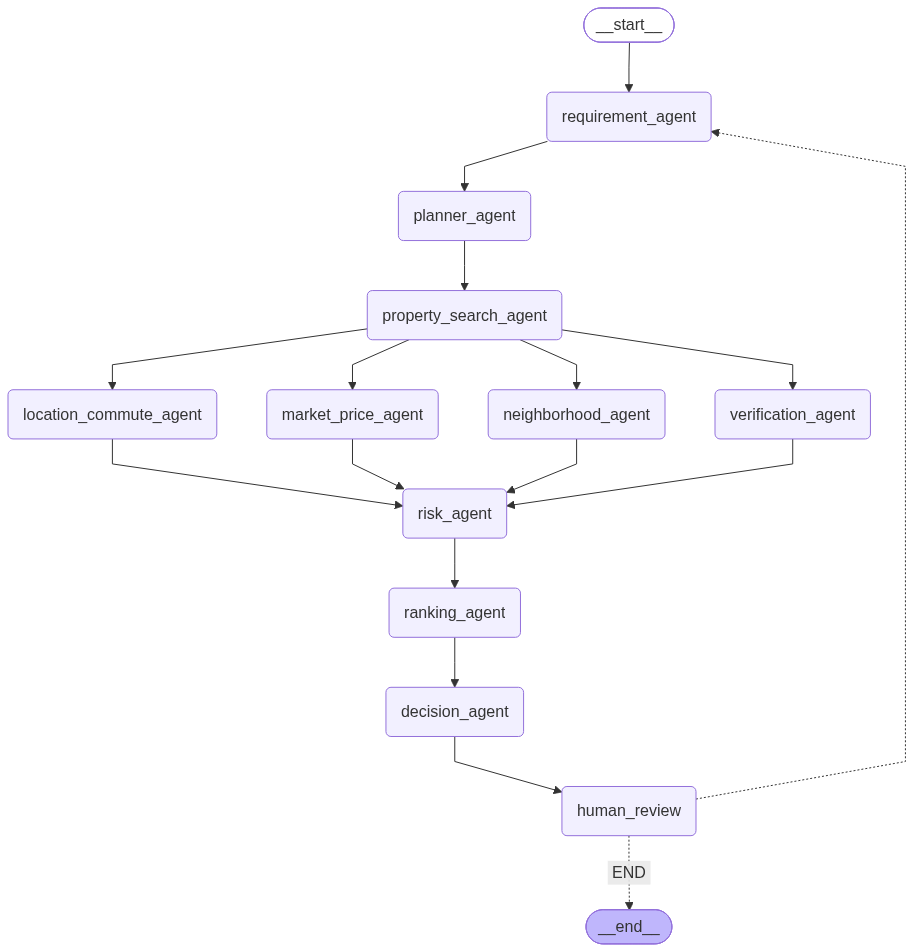

In [19]:
graph = StateGraph(PropertyState)

graph.add_node("requirement_agent", requirement_agent)
graph.add_node("planner_agent", planner_agent)
graph.add_node("property_search_agent", property_search_agent)
graph.add_node("location_commute_agent", location_commute_agent)
graph.add_node("market_price_agent", market_price_agent)
graph.add_node("neighborhood_agent", neighborhood_agent)
graph.add_node("verification_agent", verification_agent)
graph.add_node("risk_agent", risk_agent)
graph.add_node("ranking_agent", ranking_agent)
graph.add_node("decision_agent", decision_agent)
graph.add_node("human_review", human_review)

graph.add_edge(START, "requirement_agent")
graph.add_edge("requirement_agent", "planner_agent")
graph.add_edge("planner_agent", "property_search_agent")

# fan-out: 4 specialist agents run in parallel off Property Search
graph.add_edge("property_search_agent", "location_commute_agent")
graph.add_edge("property_search_agent", "market_price_agent")
graph.add_edge("property_search_agent", "neighborhood_agent")
graph.add_edge("property_search_agent", "verification_agent")

# fan-in: all 4 feed the Risk Agent
graph.add_edge("location_commute_agent", "risk_agent")
graph.add_edge("market_price_agent", "risk_agent")
graph.add_edge("neighborhood_agent", "risk_agent")
graph.add_edge("verification_agent", "risk_agent")

graph.add_edge("risk_agent", "ranking_agent")
graph.add_edge("ranking_agent", "decision_agent")
graph.add_edge("decision_agent", "human_review")

graph.add_conditional_edges(
    "human_review",
    route_after_review,
    {"END": END, "requirement_agent": "requirement_agent"},
)

memory = MemorySaver()
property_agent = graph.compile(checkpointer=memory)
property_agent

## 14. Run it

In [20]:
config = {"configurable": {"thread_id": "session-1"}}

result = property_agent.invoke(
    {
        "user_query": "I need a 2BHK in Rohini or Dwarka under 35000 rent, low risk, "
                       "and within 25km of Cyber City Gurgaon",
        "iteration": 0,
    },
    config=config,
)

print("Shortlisted candidates:", len(result["candidates"]))
print("\n--- Decision Agent recommendation ---\n")
print(result["decision"])
print("\n--- Waiting for human approval ---")
print(result["__interrupt__"][0].value["question"])

Shortlisted candidates: 8

--- Decision Agent recommendation ---

I recommend the **2BHK in Dwarka Mor for Rs. 7500/mo** (ID: 1812) as your top pick. 

- **Commute**: At just 15.6 km from Cyber City Gurgaon, it fits well within your maximum commute distance.
- **Affordability**: The price is competitive, with a -37.8% score on price vs locality, indicating good value for the area.
- **Low Risk**: It has a risk score of 0.0, aligning with your low risk tolerance.

As alternatives, consider the **2BHK for Rs. 8000/mo** (ID: 1625) which offers similar commute and amenities but at a higher price. Alternatively, the **2BHK for Rs. 6500/mo** (ID: 1748) is cheaper but has a higher risk score of 30.0, which may not align with your preferences.

--- Waiting for human approval ---
Approve this recommendation? Reply 'yes' to accept, or describe what to change.


Reply as the human reviewer. Try `"yes"` to accept, or feedback like `"budget is too tight, raise it to 45000"` to trigger a replan.

In [21]:
final = property_agent.invoke(Command(resume="yes"), config=config)

if final.get("human_feedback", "").lower().startswith("yes"):
    print("✅ Approved. Final recommendation:\n")
    print(final["decision"])
else:
    print("Loop continues — new interrupt:")
    print(final["__interrupt__"][0].value["question"])

✅ Approved. Final recommendation:

I recommend the **2BHK in Dwarka Mor for Rs. 7500/mo** (ID: 1812) as your top pick. 

- **Commute**: At just 15.6 km from Cyber City Gurgaon, it fits well within your maximum commute distance.
- **Affordability**: The price is competitive, with a -37.8% score on price vs locality, indicating good value for the area.
- **Low Risk**: It has a risk score of 0.0, aligning with your low risk tolerance.

As alternatives, consider the **2BHK for Rs. 8000/mo** (ID: 1625) which offers similar commute and amenities but at a higher price. Alternatively, the **2BHK for Rs. 6500/mo** (ID: 1748) is cheaper but has a higher risk score of 30.0, which may not align with your preferences.


## 15. Dynamic Replanning Demo

The user only tweaks the **budget** — location/commute don't change, so the Planner should skip
`location_commute_agent` and `neighborhood_agent` on the second pass and only re-run
`market_price_agent` (and the always-on `verification_agent`).

In [22]:
config2 = {"configurable": {"thread_id": "session-2"}}

r1 = property_agent.invoke(
    {"user_query": "3BHK in Kalkaji under 30000, medium risk", "iteration": 0},
    config=config2,
)
print("First pass agents_to_run:", r1["agents_to_run"])

r2 = property_agent.invoke(Command(resume="the budget is too tight, raise max budget to 45000"), config=config2)
print("\nAfter budget-only change, agents_to_run:", r2["agents_to_run"])
print("Changed fields detected by planner:", r2["changed_fields"])

r3 = property_agent.invoke(Command(resume="yes"), config=config2)
print("\n✅ Final recommendation after replanning:\n")
print(r3["decision"])

First pass agents_to_run: {'location_commute': True, 'market_price': True, 'neighborhood': True, 'verification': True}

After budget-only change, agents_to_run: {'location_commute': False, 'market_price': True, 'neighborhood': False, 'verification': True}
Changed fields detected by planner: ['budget_max']

✅ Final recommendation after replanning:

I recommend the 3BHK in Kalkaji priced at Rs. 32,000/month.

- **Space and Comfort**: At 1400 sqft, it offers ample space for comfortable living, which is ideal for a family.
- **Low Risk**: With a risk score of 0.0, this property is verified and presents a stable investment opportunity.
- **Fair Pricing**: The price is reasonable compared to the locality, with a price vs. locality score of -27.0%, indicating good value.

As an alternative, the 3BHK at Rs. 13,000/month is significantly cheaper but comes with a smaller area (900 sqft) and is flagged as a stale listing, which may indicate potential issues.


## 16. Notes / Production extensions

* **MCP tools**: swap `web_search` (Tavily) and the CSV-backed `property_search_agent` for real
  MCP servers — a listings API, Google Maps Directions API for real commute times, and a reviews
  API for the Neighborhood Agent.
* **LangSmith tracing**: set in your `.env`:
  ```
  LANGCHAIN_TRACING_V2=true
  LANGCHAIN_API_KEY=...
  LANGCHAIN_PROJECT=property-search-agent
  ```
  No code changes are needed — LangGraph picks these up automatically.
* **Subgraphs**: as the system grows, `Location & Commute`/`Market Price`/`Neighborhood`/
  `Verification` can each become their own compiled subgraph (see the *Subgraphs* pattern) if
  they need multi-step internal logic.
* **Persistence**: swap `MemorySaver` for a persistent checkpointer (e.g. SQLite/Postgres) to
  keep sessions alive across process restarts.
